<a href="https://colab.research.google.com/github/Khalidgh707/Machine-Learning-Project/blob/main/DS471ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS-471 Machine Learning Project: Energy Efficiency Prediction
**Dataset:** UCI Energy Efficiency (ENB2012) | **Problem:** Regression (predict the **Heating Load, Y1** of a building)

**Group members:**
*   Khalid A ALghamdi #210038421
*   Fahad Alkhamees #220033879
*   Abdullah S Almutairi#230031752

**Course:** DS471

**CRN**: 10700


**Deadline:** 30/11/2026

**Workflow:** by stages
1.   Data preparation and EDA
2.   Splitting
3.   Model selection
4.   Training and tuning
5.   Final evaluation and comparison


## Stage 1: Data Cleaning, Preparation and Exploration
### 1.0 Setup

In [26]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
sns.set_style("whitegrid")

### 1.1 Load the data

In [27]:
DATA_FILE = "ENB2012_data.xlsx"
DATA_URL = None

if os.path.exists(DATA_FILE):
    df = pd.read_excel(DATA_FILE)
elif DATA_URL:
    df = pd.read_excel(DATA_URL)
else:
    from google.colab import files
    uploaded = files.upload()               # choose ENB2012_data.xlsx
    df = pd.read_excel(list(uploaded.keys())[0])


df = df.rename(columns={
    "X1": "relative_compactness", "X2": "surface_area", "X3": "wall_area", "X4": "roof_area",
    "X5": "overall_height", "X6": "orientation", "X7": "glazing_area",
    "X8": "glazing_area_distribution", "Y1": "heating_load", "Y2": "cooling_load"})
df.head()

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


### 1.2 Understand the dataset (size, types, statistics)


In [28]:
print("Shape (rows, columns):", df.shape)
print()
df.info()
display(df.describe().T.round(3))
print("\nNumber of unique values per column:")
print(df.nunique())

Shape (rows, columns): (768, 10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   relative_compactness       768 non-null    float64
 1   surface_area               768 non-null    float64
 2   wall_area                  768 non-null    float64
 3   roof_area                  768 non-null    float64
 4   overall_height             768 non-null    float64
 5   orientation                768 non-null    int64  
 6   glazing_area               768 non-null    float64
 7   glazing_area_distribution  768 non-null    int64  
 8   heating_load               768 non-null    float64
 9   cooling_load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


,count,mean,std,min,25%,50%,75%,max
relative_compactness,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98
surface_area,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50
wall_area,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50
roof_area,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50
overall_height,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00
orientation,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00
glazing_area,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40
glazing_area_distribution,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00
heating_load,768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10
cooling_load,768.0,24.588,9.513,10.90,15.620,22.08,33.132,48.03



Number of unique values per column:
relative_compactness          12
surface_area                  12
wall_area                      7
roof_area                      4
overall_height                 2
orientation                    4
glazing_area                   4
glazing_area_distribution      6
heating_load                 587
cooling_load                 636
dtype: int64


Each row is one simulated building.

The 8 inputs describe the shape and glazing of the building and the 2 outputs are the energy loads.

We choose **heating_load (Y1)** as the target because the project needs one target variable.

### 1.3 Missing values, duplicates and inconsistent data

In [29]:
print("Missing values per column:\n", df.isna().sum())
print("\nTotal missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("\nColumn types:\n", df.dtypes)
print("\nUnique values of the code columns:")
print("orientation:", sorted(df['orientation'].unique()))
print("glazing_area_distribution:", sorted(df['glazing_area_distribution'].unique()))
print("glazing_area:", sorted(df['glazing_area'].unique()))
print("\nglazing_area = 0 rows and their distribution values:",
      df.loc[df.glazing_area == 0, 'glazing_area_distribution'].unique())

Missing values per column:
 relative_compactness         0
surface_area                 0
wall_area                    0
roof_area                    0
overall_height               0
orientation                  0
glazing_area                 0
glazing_area_distribution    0
heating_load                 0
cooling_load                 0
dtype: int64

Total missing values: 0
Duplicated rows: 0

Column types:
 relative_compactness         float64
surface_area                 float64
wall_area                    float64
roof_area                    float64
overall_height               float64
orientation                    int64
glazing_area                 float64
glazing_area_distribution      int64
heating_load                 float64
cooling_load                 float64
dtype: object

Unique values of the code columns:
orientation: [np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
glazing_area_distribution: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5

### 1.4 Target variable

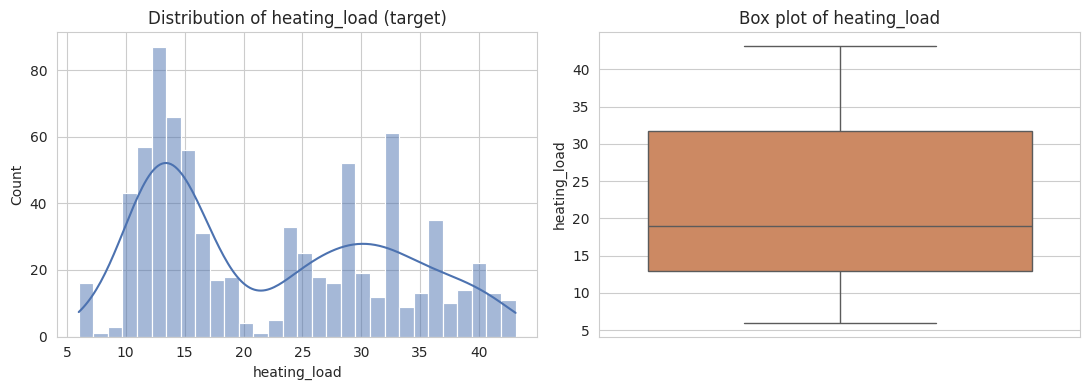

count    768.000
mean      22.307
std       10.090
min        6.010
25%       12.992
50%       18.950
75%       31.668
max       43.100
Name: heating_load, dtype: float64
Skewness: 0.36


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["heating_load"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of heating_load (target)")
sns.boxplot(y=df["heating_load"], ax=axes[1], color="#DD8452")
axes[1].set_title("Box plot of heating_load")
plt.tight_layout(); plt.savefig("figures/fig1_target_distribution.png", dpi=200); plt.show()

print(df["heating_load"].describe().round(3))
print("Skewness:", round(df['heating_load'].skew(), 3))

The target is a **continuous number**, so this is a **regression** problem.


### 1.5 Outliers (**IQR rule**)

,feature,lower_limit,upper_limit,n_outliers
0,relative_compactness,0.461,1.051,0
1,surface_area,404.250,943.250,0
2,wall_area,220.500,416.500,0
3,roof_area,21.438,339.938,0
4,overall_height,-1.750,12.250,0
5,glazing_area,-0.350,0.850,0
6,heating_load,-15.020,59.680,0


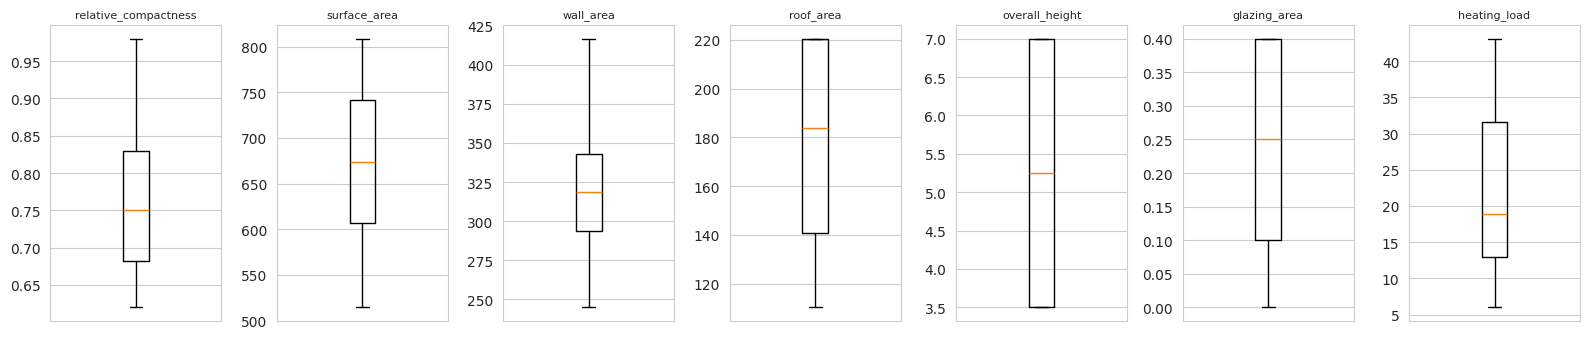

In [31]:
num_cols = ["relative_compactness", "surface_area", "wall_area", "roof_area",
            "overall_height", "glazing_area", "heating_load"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, round(low, 3), round(high, 3), int(((df[c] < low) | (df[c] > high)).sum())])
outliers = pd.DataFrame(rows, columns=["feature", "lower_limit", "upper_limit", "n_outliers"])
display(outliers)

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 3.5))
for ax, c in zip(axes, num_cols):
    ax.boxplot(df[c]); ax.set_title(c, fontsize=8); ax.set_xticks([])
plt.tight_layout(); plt.savefig("figures/fig2_boxplots.png", dpi=200); plt.show()

###1.6 Feature engineering and encoding



In [32]:
target = "heating_load"
X = df.drop(columns=[target, "cooling_load"])
y = df[target]

X = X.astype({"orientation": "category", "glazing_area_distribution": "category"})
X = pd.get_dummies(X, columns=["orientation", "glazing_area_distribution"],
                   prefix=["orient", "glazdist"], dtype=int)

print("Input columns before encoding: 8  ->  after encoding:", X.shape[1])
print(list(X.columns))
X.head()

Input columns before encoding: 8  ->  after encoding: 16
['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height', 'glazing_area', 'orient_2', 'orient_3', 'orient_4', 'orient_5', 'glazdist_0', 'glazdist_1', 'glazdist_2', 'glazdist_3', 'glazdist_4', 'glazdist_5']


,relative_compactness,surface_area,wall_area,roof_area,overall_height,glazing_area,orient_2,orient_3,orient_4,orient_5,glazdist_0,glazdist_1,glazdist_2,glazdist_3,glazdist_4,glazdist_5
0,0.98,514.5,294.0,110.25,7.0,0.0,1,0,0,0,1,0,0,0,0,0
1,0.98,514.5,294.0,110.25,7.0,0.0,0,1,0,0,1,0,0,0,0,0
2,0.98,514.5,294.0,110.25,7.0,0.0,0,0,1,0,1,0,0,0,0,0
3,0.98,514.5,294.0,110.25,7.0,0.0,0,0,0,1,1,0,0,0,0,0
4,0.90,563.5,318.5,122.50,7.0,0.0,1,0,0,0,1,0,0,0,0,0


### 1.7 Exploratory Data Analysis

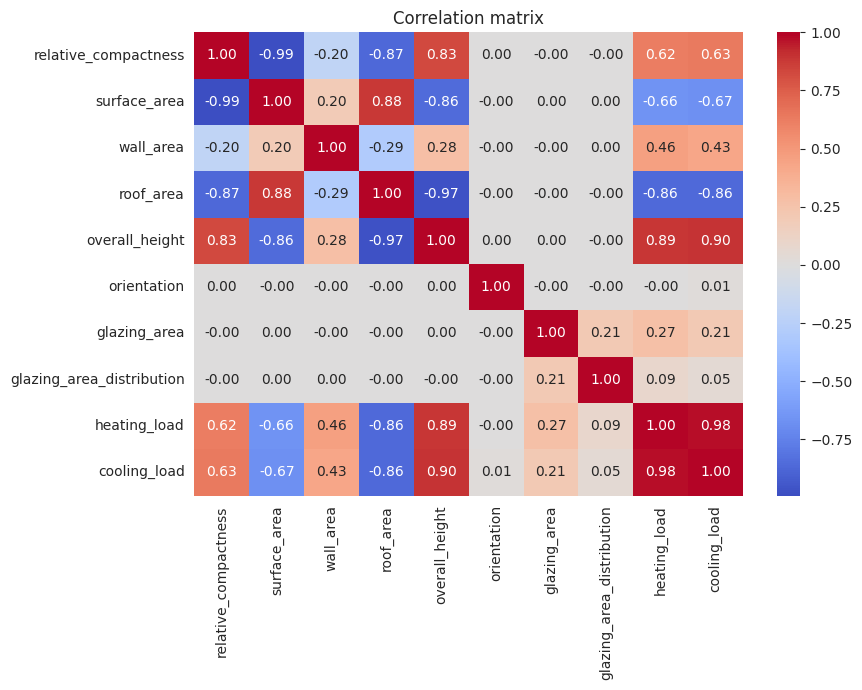

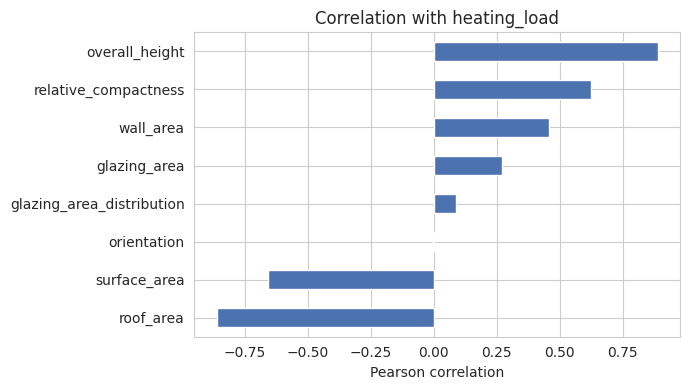

roof_area                   -0.862
surface_area                -0.658
orientation                 -0.003
glazing_area_distribution    0.087
glazing_area                 0.270
wall_area                    0.456
relative_compactness         0.622
overall_height               0.889
Name: heating_load, dtype: float64


In [33]:

corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.savefig("figures/fig3_correlation_heatmap.png", dpi=200); plt.show()


c_t = corr["heating_load"].drop(["heating_load", "cooling_load"]).sort_values()
plt.figure(figsize=(7, 4))
c_t.plot(kind="barh", color="#4C72B0")
plt.title("Correlation with heating_load"); plt.xlabel("Pearson correlation")
plt.tight_layout(); plt.savefig("figures/fig4_corr_with_target.png", dpi=200); plt.show()
print(c_t.round(3))



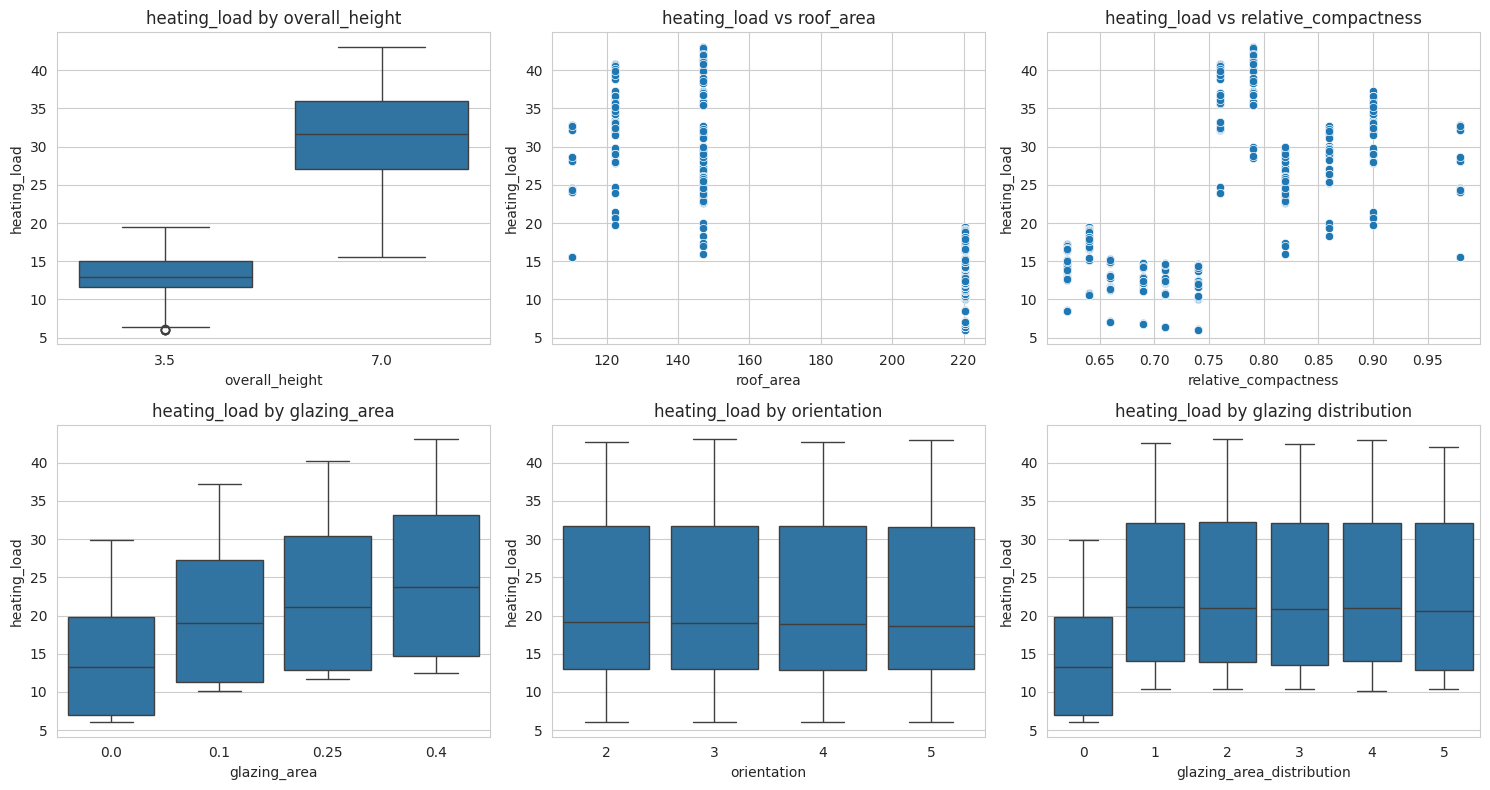

Mean heating_load by orientation:
 orientation
2    22.31
3    22.38
4    22.26
5    22.28
Name: heating_load, dtype: float64

Mean heating_load by overall_height:
 overall_height
3.5    13.34
7.0    31.28
Name: heating_load, dtype: float64


In [34]:


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.boxplot(x="overall_height", y="heating_load", data=df, ax=axes[0, 0]);          axes[0, 0].set_title("heating_load by overall_height")
sns.scatterplot(x="roof_area", y="heating_load", data=df, ax=axes[0, 1]);           axes[0, 1].set_title("heating_load vs roof_area")
sns.scatterplot(x="relative_compactness", y="heating_load", data=df, ax=axes[0, 2]); axes[0, 2].set_title("heating_load vs relative_compactness")
sns.boxplot(x="glazing_area", y="heating_load", data=df, ax=axes[1, 0]);            axes[1, 0].set_title("heating_load by glazing_area")
sns.boxplot(x="orientation", y="heating_load", data=df, ax=axes[1, 1]);             axes[1, 1].set_title("heating_load by orientation")
sns.boxplot(x="glazing_area_distribution", y="heating_load", data=df, ax=axes[1, 2]); axes[1, 2].set_title("heating_load by glazing distribution")
plt.tight_layout(); plt.savefig("figures/fig5_eda_relationships.png", dpi=200); plt.show()

print("Mean heating_load by orientation:\n", df.groupby("orientation")["heating_load"].mean().round(2))
print("\nMean heating_load by overall_height:\n", df.groupby("overall_height")["heating_load"].mean().round(2))

## Stage 2: Data Splitting
We split into **70% train, 15% validation, 15% test**.


In [35]:
import pandas as pd
from sklearn.model_selection import train_test_split

bins = pd.qcut(y, q=5, labels=False, duplicates="drop")      # 5 groups of the target

X_train, X_temp, y_train, y_temp, b_train, b_temp = train_test_split(
    X, y, bins, test_size=0.30, random_state=SEED, stratify=bins)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=b_temp)

split_table = pd.DataFrame({
    "set": ["Train", "Validation", "Test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "percent": [round(100*len(s)/len(X), 1) for s in (X_train, X_val, X_test)],
    "mean heating_load": [round(s.mean(), 2) for s in (y_train, y_val, y_test)],
    "std heating_load": [round(s.std(), 2) for s in (y_train, y_val, y_test)]})
display(split_table)

,set,rows,percent,mean heating_load,std heating_load
0,Train,537,69.9,22.27,10.09
1,Validation,115,15.0,22.60,9.85
2,Test,116,15.1,22.20,10.42


### Scaling

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)
print("Scaled train mean (about 0):", X_train_s.mean().round(4), "| std (about 1):", X_train_s.std().round(4))

Scaled train mean (about 0): -0.0 | std (about 1): 1.0


### 1.9 Most relevant features (uses the train set only)
A Random Forest is trained on the train set

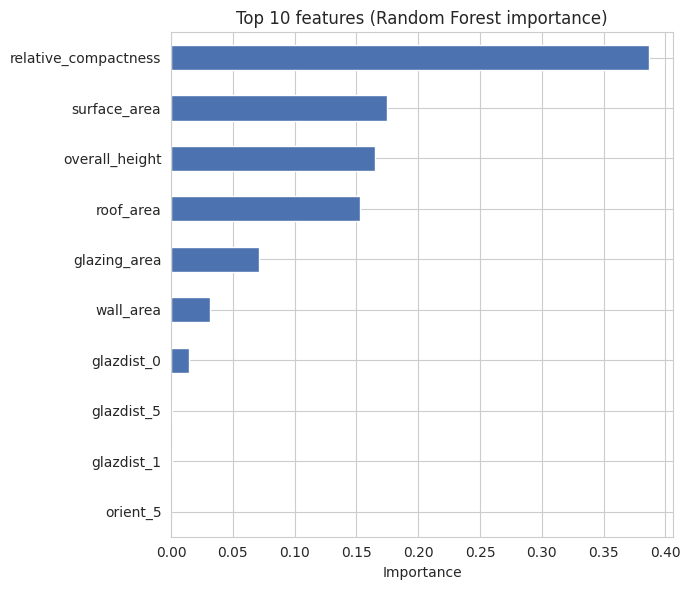

relative_compactness    0.3870
surface_area            0.1749
overall_height          0.1649
roof_area               0.1532
glazing_area            0.0715
wall_area               0.0318
glazdist_0              0.0147
glazdist_5              0.0004
glazdist_1              0.0004
orient_5                0.0003
dtype: float64


In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_tmp = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
imp = pd.Series(rf_tmp.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(7, 6))
imp.tail(10).plot(kind="barh", color="#4C72B0")
plt.title("Top 10 features (Random Forest importance)"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("figures/fig6_feature_importance.png", dpi=200); plt.show()
print(imp.sort_values(ascending=False).head(10).round(4))

## Stage 3: Model Selection and Development
The target is a continuous number, so we use **regression** models. We build three:
* Linear Regression (Ridge)
* Random Forest Regressor
* Neural Network (MLP, mandatory)

In [38]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

## Stage 4: Model Training and Hyperparameter Optimization
### 4.1 Linear Regression (Ridge) and Random Forest


In [39]:

lin = LinearRegression().fit(X_train_s, y_train)


ridge_grid = GridSearchCV(Ridge(), {"alpha": [0.001, 0.01, 0.1, 1, 10, 100]},
                          cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X_train_s, y_train)
print("Ridge best params:", ridge_grid.best_params_, "| CV RMSE:", round(-ridge_grid.best_score_, 3))
display(pd.DataFrame(ridge_grid.cv_results_)[["param_alpha", "mean_test_score"]]
        .assign(CV_RMSE=lambda d: -d.mean_test_score).drop(columns="mean_test_score"))
ridge = ridge_grid.best_estimator_

Ridge best params: {'alpha': 0.1} | CV RMSE: 2.817


,param_alpha,CV_RMSE
0,0.001,2.817327
1,0.010,2.817277
2,0.100,2.816893
3,1.000,2.818951
4,10.000,2.888566
5,100.000,3.315592


In [40]:

rf_param_grid = {"n_estimators": [100, 300],
                 "max_depth": [5, 10, 20, None],
                 "min_samples_leaf": [1, 2, 5]}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1), rf_param_grid,
                       cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_grid.fit(X_train_s, y_train)
print("Random Forest best params:", rf_grid.best_params_, "| CV RMSE:", round(-rf_grid.best_score_, 3))
res = pd.DataFrame(rf_grid.cv_results_)
res["CV_RMSE"] = -res["mean_test_score"]
display(res[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "CV_RMSE"]]
        .sort_values("CV_RMSE").head(8).round(3))
rf = rf_grid.best_estimator_

Random Forest best params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300} | CV RMSE: 0.575


,param_n_estimators,param_max_depth,param_min_samples_leaf,CV_RMSE
7,300,10,1,0.575
13,300,20,1,0.578
19,300,None,1,0.578
12,100,20,1,0.585
18,100,None,1,0.585
6,100,10,1,0.588
21,300,None,2,0.743
15,300,20,2,0.743


### 4.2 Training and validation scores (to detect overfitting / underfitting)

In [41]:
rows = []
for name, model in [("Linear Regression", lin), ("Ridge", ridge), ("Random Forest", rf)]:
    tr = reg_metrics(y_train, model.predict(X_train_s))
    va = reg_metrics(y_val,   model.predict(X_val_s))
    rows.append([name, tr["RMSE"], va["RMSE"], tr["MAE"], va["MAE"], tr["R2"], va["R2"]])
trainval = pd.DataFrame(rows, columns=["Model", "Train RMSE", "Val RMSE", "Train MAE", "Val MAE", "Train R2", "Val R2"]).round(3)
display(trainval)
trainval.to_csv("results/train_vs_validation_traditional.csv", index=False)

,Model,Train RMSE,Val RMSE,Train MAE,Val MAE,Train R2,Val R2
0,Linear Regression,2.756,2.894,1.976,2.103,0.925,0.913
1,Ridge,2.756,2.894,1.977,2.105,0.925,0.913
2,Random Forest,0.221,0.475,0.140,0.337,1.000,0.998


### 4.3 Neural Network


In [42]:
import copy
from sklearn.neural_network import MLPRegressor

y_scaler = StandardScaler().fit(y_train.values.reshape(-1, 1))
y_train_s = y_scaler.transform(y_train.values.reshape(-1, 1)).ravel()
y_val_s   = y_scaler.transform(y_val.values.reshape(-1, 1)).ravel()

def train_nn(hidden=(32,), epochs=300, early_stopping=False, patience=60, lr=0.001):
    """Train an MLP epoch by epoch. Returns the model and a history dict.
    With early_stopping=True: stop when val loss does not improve for `patience` epochs and keep the best weights."""
    m = MLPRegressor(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                     learning_rate_init=lr, batch_size=32, random_state=SEED, max_iter=1)
    hist = {"loss": [], "val_loss": [], "mae": [], "val_mae": []}
    best_val, best_model, wait = np.inf, None, 0
    for ep in range(epochs):
        m.partial_fit(X_train_s, y_train_s)
        p_tr, p_va = m.predict(X_train_s), m.predict(X_val_s)
        hist["loss"].append(mean_squared_error(y_train_s, p_tr))
        hist["val_loss"].append(mean_squared_error(y_val_s, p_va))
        hist["mae"].append(mean_absolute_error(y_train_s, p_tr))
        hist["val_mae"].append(mean_absolute_error(y_val_s, p_va))
        if hist["val_loss"][-1] < best_val - 1e-6:
            best_val, best_model, wait = hist["val_loss"][-1], copy.deepcopy(m), 0
        else:
            wait += 1
        if early_stopping and wait >= patience:
            break
    if early_stopping:
        m = best_model
    return m, hist

def nn_predict(model, Xs):
    return y_scaler.inverse_transform(model.predict(Xs).reshape(-1, 1)).ravel()

def plot_history(hist, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["loss"], label="Training loss")
    axes[0].plot(hist["val_loss"], label="Validation loss")
    axes[0].set_title(f"{title} - loss (MSE)"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
    axes[1].plot(hist["mae"], label="Training MAE")
    axes[1].plot(hist["val_mae"], label="Validation MAE")
    axes[1].set_title(f"{title} - MAE"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MAE (scaled)"); axes[1].legend()
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

 **First attempt:** a big network (two hidden layers, 128 and 64 neurons), 300 epochs, no early stopping, to see what happens.

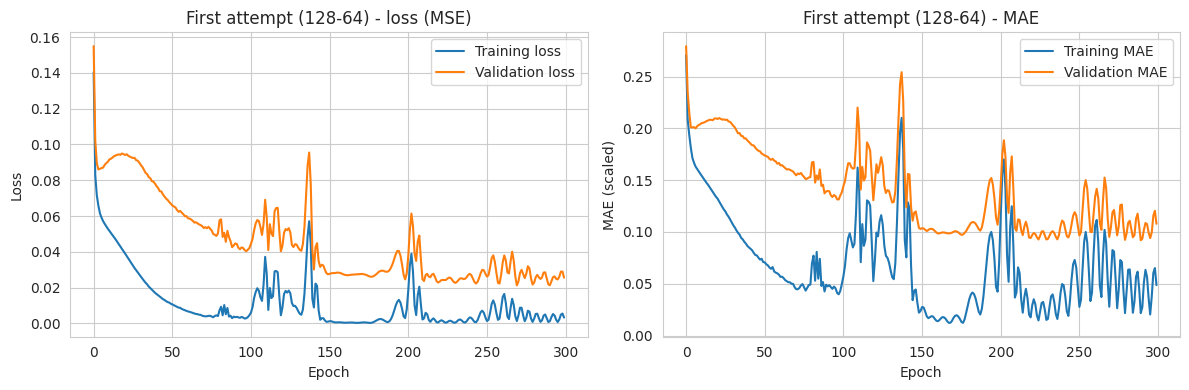

Final training loss: 0.0032
Lowest validation loss: 0.0212 at epoch 270
Final validation loss: 0.0256
First attempt: Train RMSE 0.574 | Val RMSE 1.611


In [43]:
nn_big, hist_big = train_nn(hidden=(128, 64), epochs=300, early_stopping=False)
plot_history(hist_big, "First attempt (128-64)", "figures/fig7_nn_first_attempt.png")

best_ep = int(np.argmin(hist_big["val_loss"])) + 1
print(f"Final training loss: {hist_big['loss'][-1]:.4f}")
print(f"Lowest validation loss: {min(hist_big['val_loss']):.4f} at epoch {best_ep}")
print(f"Final validation loss: {hist_big['val_loss'][-1]:.4f}")
fb = reg_metrics(y_val, nn_predict(nn_big, X_val_s)); tb = reg_metrics(y_train, nn_predict(nn_big, X_train_s))
print("First attempt: Train RMSE %.3f | Val RMSE %.3f" % (tb["RMSE"], fb["RMSE"]))

**Fix and tuning:** smaller networks and **Early Stopping** (stop when the validation loss does not improve for 60 epochs and keep the best weights). We compare several sizes using the validation loss.

In [25]:
configs = {"16": (16,), "64": (64,), "32-16": (32, 16), "64-32": (64, 32), "128-64": (128, 64), "64-32-16": (64, 32, 16)}
nn_results, nn_histories = [], {}
for name, hidden in configs.items():
    m, h = train_nn(hidden, epochs=1000, early_stopping=True, patience=60)
    nn_histories[name] = (m, h)
    va_rmse = reg_metrics(y_val, nn_predict(m, X_val_s))["RMSE"]
    nn_results.append([name, len(h["loss"]), int(np.argmin(h["val_loss"])) + 1,
                       min(h["val_loss"]), va_rmse])
nn_table = pd.DataFrame(nn_results, columns=["Hidden layers (neurons)", "Epochs run", "Best epoch",
                                             "Best val loss (scaled)", "Val RMSE (original units)"]).round(4)
display(nn_table)
nn_table.to_csv("results/nn_architecture_search.csv", index=False)

best_name = nn_table.sort_values("Val RMSE (original units)").iloc[0]["Hidden layers (neurons)"]
print("Chosen architecture:", best_name)

,Hidden layers (neurons),Epochs run,Best epoch,Best val loss (scaled),Val RMSE (original units)
0,16,152,92,0.0841,2.9223
1,64,828,768,0.0375,1.9504
2,32-16,458,398,0.0429,2.0882
3,64-32,320,260,0.0273,1.6646
4,128-64,596,536,0.0169,1.3113
5,64-32-16,322,262,0.0202,1.4312


Chosen architecture: 128-64


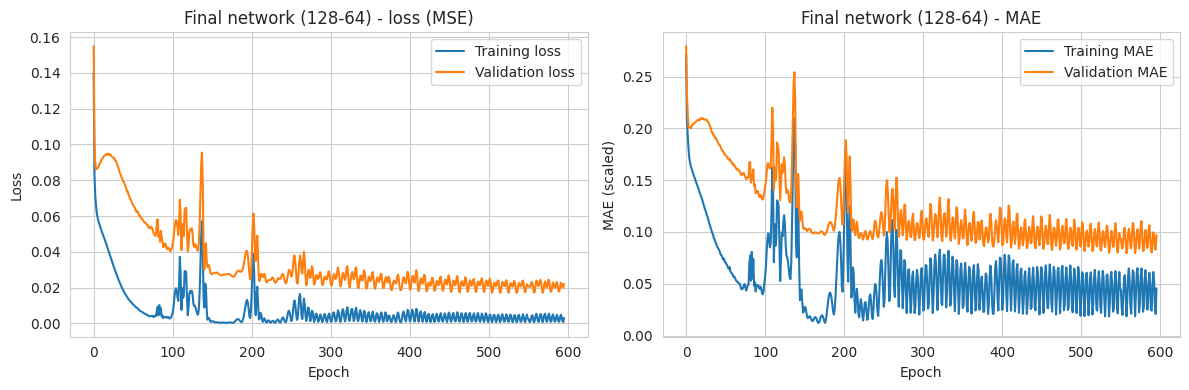

Neural Network  Train RMSE: 0.242 | Val RMSE: 1.311 | Train R2: 0.999 | Val R2: 0.982
Layers (inputs -> hidden -> output): [16, 128, 64, 1] | parameters: 10497


In [44]:
nn, hist_nn = nn_histories[best_name]
plot_history(hist_nn, f"Final network ({best_name})", "figures/fig8_nn_final.png")

tr = reg_metrics(y_train, nn_predict(nn, X_train_s))
va = reg_metrics(y_val,   nn_predict(nn, X_val_s))
print("Neural Network  Train RMSE: %.3f | Val RMSE: %.3f | Train R2: %.3f | Val R2: %.3f"
      % (tr["RMSE"], va["RMSE"], tr["R2"], va["R2"]))
n_params = sum(w.size for w in nn.coefs_) + sum(b.size for b in nn.intercepts_)
print("Layers (inputs -> hidden -> output):", [X_train_s.shape[1]] + list(nn.hidden_layer_sizes) + [1], "| parameters:", n_params)

## Stage 5: Model Final Evaluation and Comparison


In [45]:
final_models = {"Linear Regression": lin,
                "Ridge Regression": ridge,
                "Random Forest": rf}
preds = {name: m.predict(X_test_s) for name, m in final_models.items()}
preds["Neural Network"] = nn_predict(nn, X_test_s)

test_table = pd.DataFrame({name: reg_metrics(y_test, p) for name, p in preds.items()}).T
test_table = test_table[["MAE", "MSE", "RMSE", "R2"]].round(3).sort_values("RMSE")
display(test_table)
test_table.to_csv("results/final_test_comparison.csv")

,MAE,MSE,RMSE,R2
Random Forest,0.333,0.252,0.502,0.998
Neural Network,0.674,1.014,1.007,0.991
Linear Regression,2.110,8.105,2.847,0.925
Ridge Regression,2.112,8.112,2.848,0.925


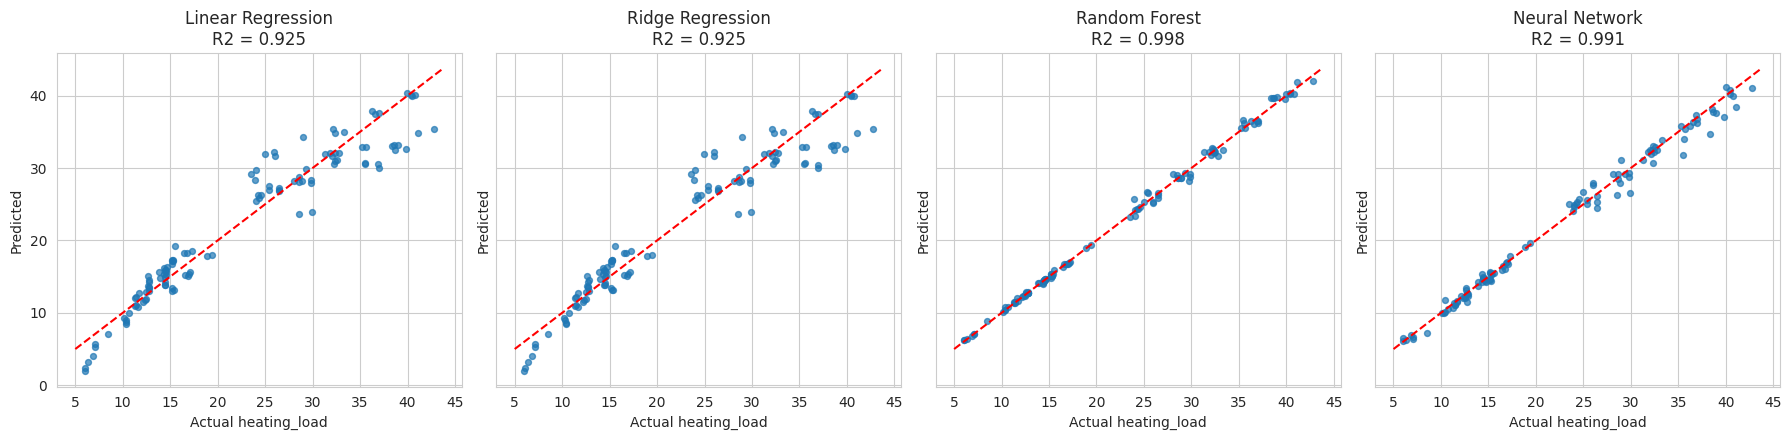

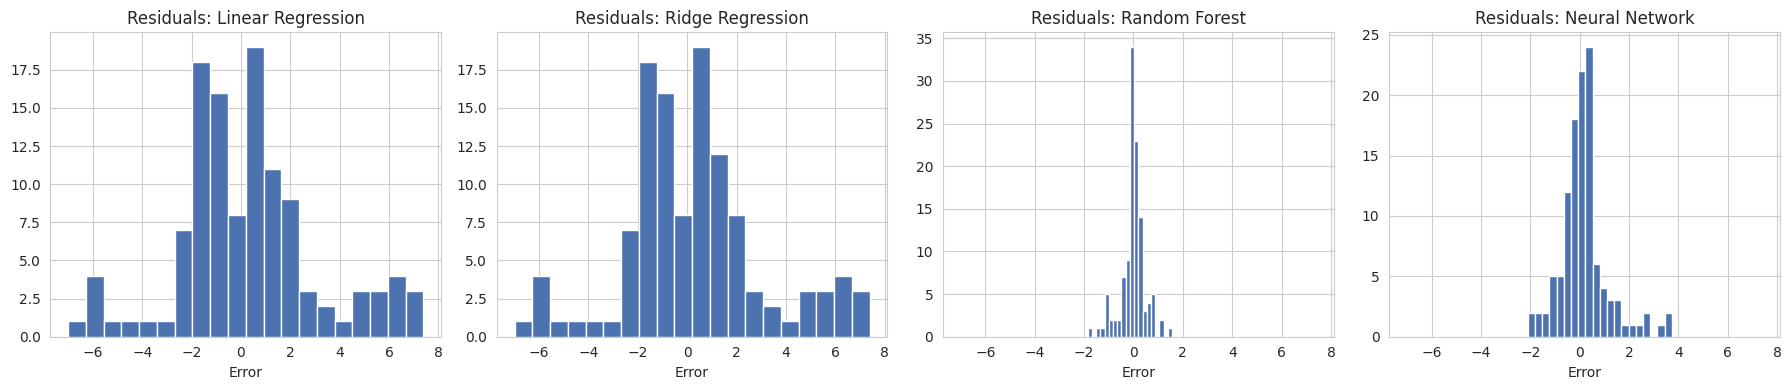

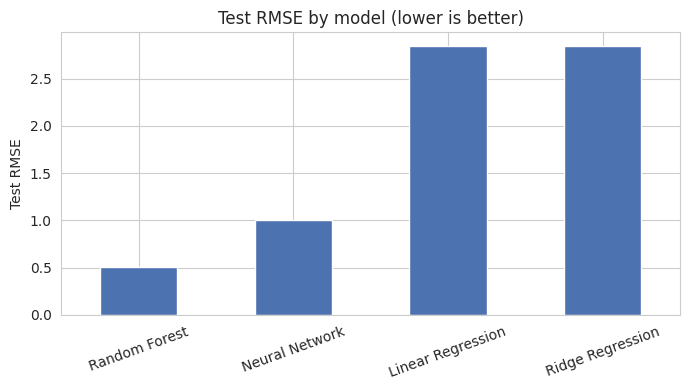

In [46]:
# Predicted vs actual, for each model
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharex=True, sharey=True)
lims = [y_test.min() - 1, y_test.max() + 1]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.7, s=18)
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name}\nR2 = {r2_score(y_test, p):.3f}")
    ax.set_xlabel("Actual heating_load"); ax.set_ylabel("Predicted")
plt.tight_layout(); plt.savefig("figures/fig9_predicted_vs_actual.png", dpi=200); plt.show()

# Residuals (actual - predicted)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, (name, p) in zip(axes, preds.items()):
    ax.hist(y_test - p, bins=20, color="#4C72B0")
    ax.set_title(f"Residuals: {name}"); ax.set_xlabel("Error")
plt.tight_layout(); plt.savefig("figures/fig10_residuals.png", dpi=200); plt.show()

# RMSE bar chart
test_table["RMSE"].plot(kind="bar", figsize=(7, 4), color="#4C72B0", rot=20)
plt.ylabel("Test RMSE"); plt.title("Test RMSE by model (lower is better)")
plt.tight_layout(); plt.savefig("figures/fig11_rmse_comparison.png", dpi=200); plt.show()

### Best Model is Random Forest

In [47]:
print("Best model on the test set (lowest RMSE):", test_table.index[0])
print(test_table)

Best model on the test set (lowest RMSE): Random Forest
                     MAE    MSE   RMSE     R2
Random Forest      0.333  0.252  0.502  0.998
Neural Network     0.674  1.014  1.007  0.991
Linear Regression  2.110  8.105  2.847  0.925
Ridge Regression   2.112  8.112  2.848  0.925
